# L2_T4 — Selfie-Gap and Skin-Tone Evaluation of the Baseline Condition Model
### Layer 2 of the Aura pipeline · Task 4

**What this notebook does:** tests the L2_T3 model on data it has never seen and that looks nothing like DermNet's
clinical close-ups: **SCIN** (`google/scin`), whose photos are mostly smartphone images taken by the public, with
dermatologist condition labels and Fitzpatrick estimates. It answers four questions the T3 numbers could not:

1. **Domain gap** — how much accuracy is lost going from clinical photos to phone photos?
2. **Skin-tone gap** — does accuracy fall for Fitzpatrick IV–VI, and for the Asian-flagged subset?
3. **Face-region proxy** — how does it do on cases flagged as head/neck, the closest SCIN gets to a selfie?
4. **Forced-choice problem** — T3 has no healthy/other class. How confidently does it label conditions it was
   never trained on? (This decides whether the model can ever be shown to a user without an abstain mechanism.)

**Data rules:** SCIN is used here for **evaluation only** (no training, no weight updates). Its license requires
attribution, a note that images were modified, and **no re-identification** of contributors. This notebook saves
only per-case results (case ID, labels, predictions), never the images.

**Honest limits, stated up front:**
- SCIN is US-based and "Asian" is not broken down; the Asian subset is **not** Filipino accuracy.
- Photos are of skin *conditions*, often on the body. Head/neck flagged cases are only a proxy for selfies.
- Out-of-scope conditions are *diseases*, not healthy skin. A true healthy-skin test still needs selfies of clear skin.
- Small subgroups give wide confidence intervals; groups under 30 cases are marked **unreliable** and not to be quoted.

**Run order:** Runtime → GPU (T4 is fine). Run cells top to bottom.

## Step 0 — Mount Drive and confirm the L2_T3 model exists

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import os, json, time, shutil

DRIVE_ROOT = "/content/drive/MyDrive/Projects/Aura/Layer2_SkinCondition"
MANIFEST_PATH = f"{DRIVE_ROOT}/manifest.json"
with open(MANIFEST_PATH) as f:
    manifest = json.load(f)
assert "model_training" in manifest, "L2_T3 has not updated the manifest."

DRIVE_MODEL_DIR = f"{DRIVE_ROOT}/models"
KERAS_DRIVE = f"{DRIVE_MODEL_DIR}/aura_l2_condition_baseline.keras"
TFLITE_DRIVE = f"{DRIVE_MODEL_DIR}/aura_l2_condition_baseline.tflite"
LABELS_DRIVE = f"{DRIVE_MODEL_DIR}/aura_l2_condition_labels.json"
for p in (KERAS_DRIVE, TFLITE_DRIVE, LABELS_DRIVE):
    assert os.path.exists(p), f"Missing {p}"

CLASSES = json.load(open(LABELS_DRIVE))["classes"]
mt = manifest["model_training"]
print("Classes:", CLASSES)
print(f"T3 test accuracy (clinical, DermNet): {mt['test_accuracy']:.3f}  macro F1: {mt['test_macro_f1']:.3f}")

LOCAL_ROOT = "/content/aura_local/Layer2_SkinCondition"
os.makedirs(LOCAL_ROOT, exist_ok=True)
DRIVE_EVAL_DIR = f"{DRIVE_ROOT}/evaluation"
os.makedirs(DRIVE_EVAL_DIR, exist_ok=True)


Mounted at /content/drive
Classes: ['acne', 'pigmentation', 'redness_sensitivity']
T3 test accuracy (clinical, DermNet): 0.754  macro F1: 0.743


## Step 1 — Record the SCIN license obligations

In [ ]:
notice = """# Data provenance notice (L2_T4)

Source: SCIN (Skin Condition Image Network) -- https://huggingface.co/datasets/google/scin
License: SCIN Data Use License (full text on the dataset page)
Citation: Ward et al., JAMA Netw Open 2024, doi:10.1001/jamanetworkopen.2024.46615

Use in this project: EVALUATION ONLY of the L2_T3 baseline. No training, no weight updates.
Obligations: keep attribution; state that images were modified (face-crop / resize / CLAHE);
never attempt to re-identify or re-link contributors.
Stored on Drive: per-case results (case_id, labels, predictions). No images are stored.
"""
open(f"{DRIVE_EVAL_DIR}/DATA_PROVENANCE_L2_T4.md", "w").write(notice)
print("✅ Provenance notice written.")


✅ Provenance notice written.


## Step 2 — Dependencies and model load

In [ ]:
!pip -q install datasets mediapipe opencv-python-headless pillow pandas scikit-learn tqdm seaborn
print("Dependencies ready.")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.6/40.6 MB 26.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.7/137.7 kB 14.0 MB/s eta 0:00:00
Dependencies ready.


In [ ]:
import numpy as np, pandas as pd, tensorflow as tf
print("TensorFlow", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))
local_keras = f"{LOCAL_ROOT}/aura_l2_condition_baseline.keras"
shutil.copy2(KERAS_DRIVE, local_keras)
model = tf.keras.models.load_model(local_keras)
print("Model loaded. Input:", model.input_shape, "Output:", model.output_shape)


TensorFlow 2.21.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Model loaded. Input: (None, 224, 224, 3) Output: (None, 3)


## Step 3 — Load SCIN and **inspect before trusting**
Column names are printed so you can see exactly what this version of the dataset contains before any mapping runs.

In [ ]:
from datasets import load_dataset
scin = load_dataset("google/scin", split="train")
print("SCIN cases:", len(scin))

IMAGE_COLS = [c for c in ("image_1_path", "image_2_path", "image_3_path") if c in scin.column_names]
meta = scin.select_columns([c for c in scin.column_names if c not in IMAGE_COLS]).to_pandas()
meta["dataset_index"] = np.arange(len(meta))

must_have = ["case_id", "dermatologist_skin_condition_on_label_name"]
missing = [c for c in must_have if c not in meta.columns]
assert not missing, f"SCIN schema changed -- missing {missing}. Columns: {list(meta.columns)}"

label_cols = [c for c in meta.columns if "condition" in c and ("label" in c or "weighted" in c)]
print("\nCondition-label columns:", label_cols)
for c in label_cols[:3]:
    print(f"\n{c} -- 3 sample values:")
    print(meta[c].dropna().head(3).tolist())


README.md:   0%|          | 0.00/24.5k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/26 [00:00<?, ?it/s]

Some datasets params were ignored: ['splits', 'download_size', 'dataset_size']. Make sure to use only valid params for the dataset builder and to have a up-to-date version of the `datasets` library.


Resolving data files:   0%|          | 0/26 [00:00<?, ?it/s]

data/train-00000-of-00026.parquet: reconstructing file:   0%|          |  0.00B /  493MB            

...

data/train-00025-of-00026.parquet: reconstructing file:   0%|          |  0.00B /  487MB            

data/train-00025-of-00026.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/5033 [00:00<?, ? examples/s]

Loading dataset shards:   0%|          | 0/19 [00:00<?, ?it/s]

SCIN cases: 5033

Condition-label columns: ['dermatologist_skin_condition_on_label_name', 'weighted_skin_condition_label']

dermatologist_skin_condition_on_label_name -- 3 sample values:
["['Inflicted skin lesions', 'Eczema', 'Irritant Contact Dermatitis']", "['Prurigo nodularis', 'Actinic Keratosis', 'SCC/SCCIS']", "['Impetigo', 'Herpes Zoster', 'Bullous dermatitis']"]

weighted_skin_condition_label -- 3 sample values:
["{'Inflicted skin lesions': 0.41, 'Eczema': 0.41, 'Irritant Contact Dermatitis': 0.18}", "{'Prurigo nodularis': 0.41, 'SCC/SCCIS': 0.41, 'Actinic Keratosis': 0.18}", "{'Impetigo': 0.55, 'Herpes Zoster': 0.23, 'Bullous dermatitis': 0.23}"]


## Step 4 — Parse dermatologist condition labels and map them to Aura's categories
Same keyword idea as L2_T2 so the categories mean the same thing, plus extra exclusions that matter in SCIN
(hypopigmentation and vitiligo are *loss* of pigment, not hyperpigmentation). A case counts as **in-scope** only
when its top-weighted condition maps to a category with weight ≥ 0.5; otherwise it is **out-of-scope** (a disease
the model was never trained on) or **ambiguous** (dropped). **Review the printed condition names.**

In [ ]:
import ast, json as _json
from collections import defaultdict

CATEGORY_RULES = {
    "acne": {"include": ["acne", "comedo"], "exclude": ["keloidalis", "scar", "histology", "rosacea", "nevus comedonicus"]},
    "redness_sensitivity": {"include": ["rosacea", "perioral"], "exclude": ["rhinophyma", "histology"]},
    "pigmentation": {"include": ["lentigo", "sun damaged", "melasma", "freckle", "pigment", "hyperpig", "ephelid"],
                     "exclude": ["maligna", "melanoma", "melanocytic", "nevi", "nevus", "incontinentia", "purpuric",
                                 "histology", "hypopigment", "depigment", "vitiligo", "basal cell", "carcinoma", "keratosis"]},
}
def map_condition(name):
    n = str(name).strip().lower()
    for cat, rule in CATEGORY_RULES.items():
        if any(k in n for k in rule["include"]) and not any(k in n for k in rule["exclude"]):
            return cat
    return None

def parse_weights(row):
    """Return {condition_name: weight}. Tries the weighted column first, then the plain name list."""
    for col in ("weighted_skin_condition_label",):
        v = row.get(col)
        if isinstance(v, dict) and v:
            return {str(k): float(w) for k, w in v.items()}
        if isinstance(v, str) and v.strip():
            for loader in (_json.loads, ast.literal_eval):
                try:
                    d = loader(v)
                    if isinstance(d, dict) and d:
                        return {str(k): float(w) for k, w in d.items()}
                except Exception:
                    pass
    v = row.get("dermatologist_skin_condition_on_label_name")
    names = None
    if isinstance(v, (list, tuple, np.ndarray)):
        names = [str(x) for x in v]
    elif isinstance(v, str) and v.strip():
        for loader in (_json.loads, ast.literal_eval):
            try:
                d = loader(v)
                if isinstance(d, (list, tuple)):
                    names = [str(x) for x in d]; break
            except Exception:
                pass
        if names is None:
            names = [v]
    if names:
        return {n: 1.0 / len(names) for n in names}
    return {}

meta["weights"] = meta.apply(parse_weights, axis=1)
parsed = meta["weights"].apply(bool).sum()
print(f"Cases with a parseable dermatologist condition label: {parsed} of {len(meta)}")
assert parsed > 500, "Almost no labels parsed -- check the sample values printed in Step 3 and adjust parse_weights."

def classify(w):
    if not w: return ("unlabeled", None, 0.0)
    top, tw = max(w.items(), key=lambda kv: kv[1])
    if tw < 0.5: return ("ambiguous", None, tw)
    cat = map_condition(top)
    return ("in_scope", cat, tw) if cat else ("out_of_scope", None, tw)

res = meta["weights"].apply(classify)
meta["scope"] = [r[0] for r in res]; meta["true_cat"] = [r[1] for r in res]
meta["top_condition"] = [max(w.items(), key=lambda kv: kv[1])[0] if w else None for w in meta["weights"]]
print("\n", meta["scope"].value_counts().to_string())
print("\nIn-scope cases per category:\n", meta[meta.scope == "in_scope"]["true_cat"].value_counts().to_string())

print("\nCondition names mapped to each category (CHECK THESE):")
for cat in CATEGORY_RULES:
    s = meta[(meta.scope == "in_scope") & (meta.true_cat == cat)]["top_condition"].value_counts()
    print(f"\n[{cat}]"); print(s.to_string())
print("\nTop 25 out-of-scope conditions (model has never seen these):")
print(meta[meta.scope == "out_of_scope"]["top_condition"].value_counts().head(25).to_string())


Cases with a parseable dermatologist condition label: 3061 of 5033

 scope
out_of_scope    2122
unlabeled       1972
ambiguous        837
in_scope         102

In-scope cases per category:
 true_cat
acne                   51
redness_sensitivity    38
pigmentation           13

Condition names mapped to each category (CHECK THESE):

[acne]
top_condition
Acne             50
Acne urticata     1

[redness_sensitivity]
top_condition
Rosacea                25
Perioral Dermatitis    13

[pigmentation]
top_condition
Post-Inflammatory hyperpigmentation                                           6
Melasma                                                                       3
Hemosiderin pigmentation of skin due to venous insufficiency                  1
Hyperpigmentation                                                             1
Hemosiderin pigmentation of lower limb due to varicose veins of lower limb    1
Melanin pigmentation due to exogenous substance                               1

Top 2

**Checkpoint:** if a name under a category isn't really that condition, add it to the category's `exclude` list and
re-run Step 4. If a category has under ~30 cases, its numbers below will be marked unreliable.

## Step 5 — Subgroup attributes (Fitzpatrick, Asian flag, head/neck, shot type)

In [ ]:
def parse_fst(v):
    if isinstance(v, str) and v.startswith("FST") and v[3:].isdigit():
        n = int(v[3:]); return n if 1 <= n <= 6 else None
    return None
def derm_fst(row):
    labs = [parse_fst(row.get(f"dermatologist_fitzpatrick_skin_type_label_{i}")) for i in (1, 2, 3)]
    labs = [l for l in labs if l is not None]
    if not labs or max(labs) - min(labs) > 1: return None
    return int(np.floor(np.median(labs) + 0.5))
def is_yes(v):
    return v is True or (isinstance(v, str) and v.strip().upper() in ("YES", "TRUE"))

meta["fst"] = meta.apply(derm_fst, axis=1)
meta["fst_group"] = pd.cut(meta["fst"], bins=[0, 2, 4, 6], labels=["FST I-II", "FST III-IV", "FST V-VI"])
meta["is_asian"] = meta["race_ethnicity_asian"].map(is_yes) if "race_ethnicity_asian" in meta else False
meta["head_neck"] = meta["body_parts_head_or_neck"].map(is_yes) if "body_parts_head_or_neck" in meta else False

ev = meta[meta.scope.isin(["in_scope", "out_of_scope"])].copy()
print("Evaluation pool:", len(ev), "cases")
print("\nFitzpatrick group counts (in-scope only):")
print(ev[ev.scope == "in_scope"]["fst_group"].value_counts(dropna=False).to_string())
print("\nAsian-flagged in-scope:", int(ev[ev.scope == "in_scope"]["is_asian"].sum()),
      "| head/neck in-scope:", int(ev[ev.scope == "in_scope"]["head_neck"].sum()))


Evaluation pool: 2224 cases

Fitzpatrick group counts (in-scope only):
fst_group
FST I-II      43
FST III-IV    42
FST V-VI      12
NaN            5

Asian-flagged in-scope: 4 | head/neck in-scope: 54


## Step 6 — Preprocess and predict (same pipeline as T2/T3: face-crop-or-whole-image, 224×224, CLAHE)

In [ ]:
import cv2, urllib.request
import mediapipe as mp
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision as mp_vision
from PIL import Image
from tqdm.auto import tqdm

IMG = 224
fd_path = f"{LOCAL_ROOT}/blaze_face_short_range.tflite"
if not os.path.exists(fd_path):
    urllib.request.urlretrieve(
        "https://storage.googleapis.com/mediapipe-models/face_detector/blaze_face_short_range/float16/1/blaze_face_short_range.tflite", fd_path)
detector = mp_vision.FaceDetector.create_from_options(
    mp_vision.FaceDetectorOptions(base_options=mp_python.BaseOptions(model_asset_path=fd_path)))

def preprocess(img_rgb, margin=0.25):
    h, w = img_rgb.shape[:2]
    r = detector.detect(mp.Image(image_format=mp.ImageFormat.SRGB, data=np.ascontiguousarray(img_rgb)))
    found = bool(r.detections)
    crop = img_rgb
    if found:
        b = r.detections[0].bounding_box
        mx, my = int(b.width * margin), int(b.height * margin)
        x1, y1 = max(0, b.origin_x - mx), max(0, b.origin_y - my)
        x2, y2 = min(w, b.origin_x + b.width + mx), min(h, b.origin_y + b.height + my)
        if x2 > x1 and y2 > y1: crop = img_rgb[y1:y2, x1:x2]
    out = cv2.resize(crop, (IMG, IMG), interpolation=cv2.INTER_AREA)
    l, a, bb = cv2.split(cv2.cvtColor(out, cv2.COLOR_RGB2LAB))
    out = cv2.cvtColor(cv2.merge([cv2.createCLAHE(2.0, (8, 8)).apply(l), a, bb]), cv2.COLOR_LAB2RGB)
    # JPEG round-trip (q92) to match how T3 training images were stored
    ok, buf = cv2.imencode(".jpg", cv2.cvtColor(out, cv2.COLOR_RGB2BGR), [cv2.IMWRITE_JPEG_QUALITY, 92])
    out = cv2.cvtColor(cv2.imdecode(buf, cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)
    return out.astype("float32"), found

rows = []
for r in tqdm(ev.itertuples(index=False), total=len(ev), desc="SCIN cases"):
    rec = scin[int(r.dataset_index)]
    probs, faces = [], []
    for k in IMAGE_COLS:
        im = rec.get(k)
        if im is None: continue
        x, found = preprocess(np.array(im.convert("RGB")))
        probs.append(model.predict(x[None], verbose=0)[0]); faces.append(found)
    if not probs: continue
    rows.append({"case_id": str(r.case_id), "mean_probs": np.mean(probs, axis=0), "n_images": len(probs), "face_found_any": any(faces)})

pred = pd.DataFrame(rows)
ev["case_id"] = ev["case_id"].astype(str)
res_df = ev.merge(pred, on="case_id", how="inner")
P = np.stack(res_df["mean_probs"].values)
res_df["pred_cat"] = [CLASSES[i] for i in P.argmax(1)]
res_df["confidence"] = P.max(1)
print(f"\nPredicted {len(res_df)} cases ({int(res_df.face_found_any.sum())} had a detected face in at least one image).")


SCIN cases:   0%|          | 0/2224 [00:00<?, ?it/s]


Predicted 2224 cases (397 had a detected face in at least one image).


## Step 7 — Results on in-scope cases: overall, then by subgroup
Case-level prediction = mean softmax over that case's images. Bootstrap 95% intervals (1,000 resamples). Groups under
30 cases are flagged **unreliable**.

IN-SCOPE n=102   majority-class baseline: 0.500
Overall accuracy 0.520 (95% CI 0.422-0.618) | macro F1 0.499

For comparison -- T3 on DermNet clinical test: accuracy 0.754, macro F1 0.743
DOMAIN GAP (accuracy): +0.235

                     precision    recall  f1-score   support

               acne      0.667     0.549     0.602        51
       pigmentation      0.321     0.692     0.439        13
redness_sensitivity      0.500     0.421     0.457        38

           accuracy                          0.520       102
          macro avg      0.496     0.554     0.499       102
       weighted avg      0.561     0.520     0.527       102



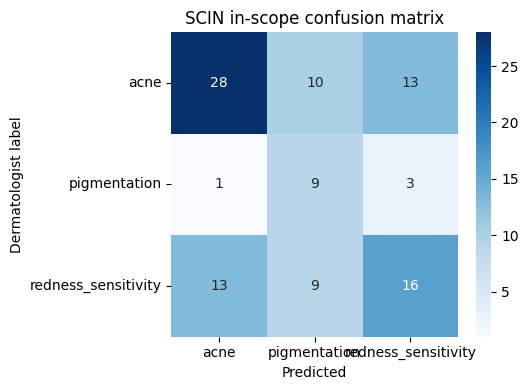


                         subgroup   n  accuracy  macro_f1  ci_lo  ci_hi       reliability
                    All in-scope 102     0.520     0.499  0.422  0.618                OK
                        FST I-II  43     0.535     0.456  0.395  0.674                OK
                      FST III-IV  42     0.476     0.423  0.333  0.619                OK
                        FST V-VI  12     0.417     0.321  0.167  0.667 UNRELIABLE (n<30)
           Fitzpatrick unlabeled   5     1.000     1.000  1.000  1.000 UNRELIABLE (n<30)
                   Asian-flagged   4     0.500     0.389  0.000  1.000 UNRELIABLE (n<30)
               Not Asian-flagged  98     0.520     0.502  0.429  0.612                OK
Head/neck flagged (selfie proxy)  54     0.444     0.398  0.315  0.574                OK
                   Not head/neck  48     0.604     0.593  0.479  0.750                OK
          Face detected in image  48     0.458     0.434  0.312  0.604                OK
                No 

In [ ]:
from sklearn.metrics import f1_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt, seaborn as sns
rng = np.random.default_rng(0)
MIN_N = 30

ins = res_df[res_df.scope == "in_scope"].copy()
ins = ins[ins["true_cat"].isin(CLASSES)]
assert len(ins) >= 60, f"Only {len(ins)} in-scope cases -- too few to evaluate."

def metrics(d):
    y, p = d["true_cat"].values, d["pred_cat"].values
    acc = float((y == p).mean())
    mf1 = float(f1_score(y, p, average="macro", labels=CLASSES, zero_division=0))
    boots = []
    for _ in range(1000):
        i = rng.integers(0, len(d), len(d))
        boots.append((y[i] == p[i]).mean())
    lo, hi = np.percentile(boots, [2.5, 97.5])
    return acc, mf1, lo, hi

maj = ins["true_cat"].value_counts(normalize=True).max()
acc, mf1, lo, hi = metrics(ins)
print(f"IN-SCOPE n={len(ins)}   majority-class baseline: {maj:.3f}")
print(f"Overall accuracy {acc:.3f} (95% CI {lo:.3f}-{hi:.3f}) | macro F1 {mf1:.3f}")
print(f"\nFor comparison -- T3 on DermNet clinical test: accuracy {mt['test_accuracy']:.3f}, macro F1 {mt['test_macro_f1']:.3f}")
print(f"DOMAIN GAP (accuracy): {mt['test_accuracy'] - acc:+.3f}\n")
print(classification_report(ins["true_cat"], ins["pred_cat"], labels=CLASSES, digits=3, zero_division=0))

cm = confusion_matrix(ins["true_cat"], ins["pred_cat"], labels=CLASSES)
plt.figure(figsize=(5.5, 4)); sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel("Predicted"); plt.ylabel("Dermatologist label"); plt.title("SCIN in-scope confusion matrix"); plt.tight_layout(); plt.show()

subgroups = []
def add(name, mask):
    d = ins[mask]
    if len(d) == 0: subgroups.append((name, 0, None, None, None, None, "no cases")); return
    a, f, l, h = metrics(d)
    subgroups.append((name, len(d), a, f, l, h, "OK" if len(d) >= MIN_N else "UNRELIABLE (n<30)"))
add("All in-scope", ins.index == ins.index)
for g in ["FST I-II", "FST III-IV", "FST V-VI"]: add(g, ins["fst_group"] == g)
add("Fitzpatrick unlabeled", ins["fst_group"].isna())
add("Asian-flagged", ins["is_asian"])
add("Not Asian-flagged", ~ins["is_asian"])
add("Head/neck flagged (selfie proxy)", ins["head_neck"])
add("Not head/neck", ~ins["head_neck"])
add("Face detected in image", ins["face_found_any"])
add("No face detected", ~ins["face_found_any"])
for c in CLASSES: add(f"True class = {c}", ins["true_cat"] == c)

sg = pd.DataFrame(subgroups, columns=["subgroup", "n", "accuracy", "macro_f1", "ci_lo", "ci_hi", "reliability"]).round(3)
print("\n", sg.to_string(index=False))


**How to read the table:** only quote rows marked `OK`. Compare `FST V-VI` against `FST I-II` — the gap, not the
absolute number, is the fairness signal. If `FST V-VI` is unreliable, say so; do not fill it in with a guess.

## Step 8 — The forced-choice problem (no healthy / "other" class)
For conditions the model was **never trained on**, it still must answer. This step measures how confident it is anyway.
If out-of-scope cases are predicted about as confidently as in-scope ones, a confidence threshold cannot protect users and
the model needs an explicit "none of these" output before it ever reaches the app.

Out-of-scope cases: 2122 | in-scope cases: 102

Median confidence  in-scope: 0.558   out-of-scope: 0.659

What the model calls the out-of-scope conditions:
pred_cat
acne                   0.506
pigmentation           0.439
redness_sensitivity    0.056

Abstention trade-off (answer only when confidence >= threshold):
 threshold  in_scope_coverage  in_scope_accuracy_when_answering  out_of_scope_still_labelled
       0.0              1.000                             0.520                        1.000
       0.5              0.745                             0.592                        0.809
       0.6              0.451                             0.804                        0.603
       0.7              0.324                             0.879                        0.434
       0.8              0.206                             0.857                        0.273
       0.9              0.098                             0.900                        0.122


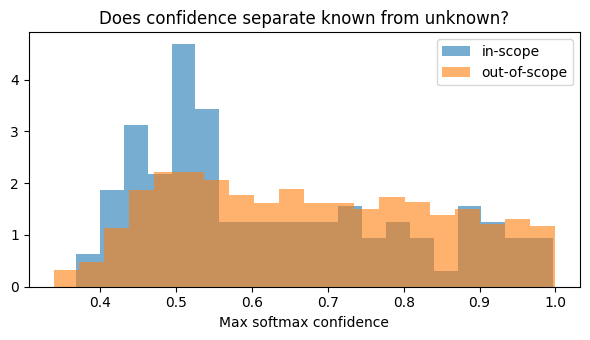

In [ ]:
oos = res_df[res_df.scope == "out_of_scope"]
print(f"Out-of-scope cases: {len(oos)} | in-scope cases: {len(ins)}\n")
print(f"Median confidence  in-scope: {ins.confidence.median():.3f}   out-of-scope: {oos.confidence.median():.3f}")
print("\nWhat the model calls the out-of-scope conditions:")
print(oos["pred_cat"].value_counts(normalize=True).round(3).to_string())

ins["correct"] = ins["true_cat"] == ins["pred_cat"]
rows = []
for t in [0.0, 0.5, 0.6, 0.7, 0.8, 0.9]:
    kept = ins[ins.confidence >= t]
    rows.append({"threshold": t,
                 "in_scope_coverage": round(len(kept) / len(ins), 3),
                 "in_scope_accuracy_when_answering": round(float(kept.correct.mean()), 3) if len(kept) else None,
                 "out_of_scope_still_labelled": round(float((oos.confidence >= t).mean()), 3) if len(oos) else None})
thr = pd.DataFrame(rows)
print("\nAbstention trade-off (answer only when confidence >= threshold):")
print(thr.to_string(index=False))

plt.figure(figsize=(6, 3.5))
plt.hist(ins.confidence, bins=20, alpha=.6, label="in-scope", density=True)
plt.hist(oos.confidence, bins=20, alpha=.6, label="out-of-scope", density=True)
plt.xlabel("Max softmax confidence"); plt.legend(); plt.title("Does confidence separate known from unknown?"); plt.tight_layout(); plt.show()


**How to read it:** the `out_of_scope_still_labelled` column is the false-alarm rate — the share of unrelated conditions
that still get an acne/redness/pigmentation label at that threshold. Look for a threshold where it drops a lot while
`in_scope_coverage` stays reasonable. If no such threshold exists, confidence is not a usable abstain signal.

## Step 9 — Shipping-format check (TFLite vs Keras on SCIN) and readiness gate

In [ ]:
try:
    from ai_edge_litert.interpreter import Interpreter
except Exception:
    Interpreter = tf.lite.Interpreter
local_tfl = f"{LOCAL_ROOT}/aura_l2_condition_baseline.tflite"
shutil.copy2(TFLITE_DRIVE, local_tfl)
it = Interpreter(model_path=local_tfl); it.allocate_tensors()
i_d, o_d = it.get_input_details()[0], it.get_output_details()[0]

sample = ins.sample(min(40, len(ins)), random_state=1)
agree = 0
for r in sample.itertuples(index=False):
    rec = scin[int(r.dataset_index)]
    im = next((rec[k] for k in IMAGE_COLS if rec.get(k) is not None), None)
    x, _ = preprocess(np.array(im.convert("RGB")))
    it.set_tensor(i_d["index"], x[None].astype("float32")); it.invoke()
    agree += int(it.get_tensor(o_d["index"])[0].argmax() == model.predict(x[None], verbose=0)[0].argmax())
print(f"TFLite vs Keras top-1 agreement on {len(sample)} SCIN images: {agree}/{len(sample)}")

# Informational readiness gate -- thresholds are project targets, not clinical standards
reliable = sg[sg.reliability == "OK"].set_index("subgroup")
gate = []
gate.append(("Overall macro F1 >= 0.70", mf1 >= 0.70, f"{mf1:.3f}"))
if "Head/neck flagged (selfie proxy)" in reliable.index:
    v = reliable.loc["Head/neck flagged (selfie proxy)", "macro_f1"]; gate.append(("Head/neck macro F1 >= 0.70", v >= 0.70, f"{v:.3f}"))
else:
    gate.append(("Head/neck macro F1 >= 0.70", None, "n<30 -- cannot assess"))
if {"FST I-II", "FST V-VI"} <= set(reliable.index):
    gap = reliable.loc["FST I-II", "accuracy"] - reliable.loc["FST V-VI", "accuracy"]
    gate.append(("FST I-II minus V-VI accuracy gap <= 0.10", gap <= 0.10, f"{gap:+.3f}"))
else:
    gate.append(("FST I-II minus V-VI accuracy gap <= 0.10", None, "a group has n<30 -- cannot assess"))
print("\nReadiness gate (informational):")
for name, ok, val in gate:
    print(f"  {'PASS' if ok else ('FAIL' if ok is False else 'UNKNOWN')}  {name}  [{val}]")


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


TFLite vs Keras top-1 agreement on 40 SCIN images: 40/40

Readiness gate (informational):
  FAIL  Overall macro F1 >= 0.70  [0.499]
  UNKNOWN  Head/neck macro F1 >= 0.70  [0.398]
  UNKNOWN  FST I-II minus V-VI accuracy gap <= 0.10  [a group has n<30 -- cannot assess]


## Step 10 — Save results to Drive (per-case CSV, no images) and verify after remount

In [ ]:
out_cols = ["case_id", "scope", "top_condition", "true_cat", "pred_cat", "confidence", "fst", "fst_group",
            "is_asian", "head_neck", "face_found_any", "n_images"]
local_csv = f"{LOCAL_ROOT}/scin_eval_results.csv"
res_df[out_cols].to_csv(local_csv, index=False)
local_sg = f"{LOCAL_ROOT}/scin_eval_subgroups.csv"; sg.to_csv(local_sg, index=False)
local_thr = f"{LOCAL_ROOT}/scin_eval_abstention.csv"; thr.to_csv(local_thr, index=False)

for p in (local_csv, local_sg, local_thr):
    dst = f"{DRIVE_EVAL_DIR}/{os.path.basename(p)}"
    shutil.copy2(p, dst); time.sleep(1)
    assert os.path.getsize(dst) == os.path.getsize(p), f"SIZE MISMATCH {p}"
drive.flush_and_unmount(); time.sleep(3); drive.mount('/content/drive')
for p in (local_csv, local_sg, local_thr):
    dst = f"{DRIVE_EVAL_DIR}/{os.path.basename(p)}"
    assert os.path.exists(dst) and os.path.getsize(dst) == os.path.getsize(p), f"MISSING AFTER REMOUNT {dst}"
    print("  ✅", os.path.basename(dst), f"{os.path.getsize(dst)/1e3:.1f} KB")


Mounted at /content/drive
  ✅ scin_eval_results.csv 228.6 KB
  ✅ scin_eval_subgroups.csv 0.8 KB
  ✅ scin_eval_abstention.csv 0.2 KB


## Step 11 — Update the manifest (written last)

In [ ]:
manifest["selfie_gap_eval"] = {
    "generated_at_utc": pd.Timestamp.utcnow().isoformat(),
    "dataset": "SCIN (google/scin), evaluation only",
    "in_scope_cases": int(len(ins)), "out_of_scope_cases": int(len(oos)),
    "scin_accuracy": round(acc, 4), "scin_macro_f1": round(mf1, 4),
    "scin_accuracy_ci95": [round(float(lo), 4), round(float(hi), 4)],
    "majority_baseline": round(float(maj), 4),
    "dermnet_test_accuracy": mt["test_accuracy"],
    "domain_gap_accuracy": round(mt["test_accuracy"] - acc, 4),
    "subgroups": sg.to_dict(orient="records"),
    "out_of_scope_median_confidence": round(float(oos.confidence.median()), 4) if len(oos) else None,
    "in_scope_median_confidence": round(float(ins.confidence.median()), 4),
    "abstention_table": thr.to_dict(orient="records"),
    "readiness_gate": [{"check": n, "result": ("PASS" if ok else "FAIL" if ok is False else "UNKNOWN"), "value": v} for n, ok, v in gate],
    "caveats": [
        "SCIN is US-based; Asian-flagged subset is not Filipino accuracy.",
        "Out-of-scope = other diseases, not healthy skin; a clear-skin test still needs selfies.",
        "Head/neck flagged cases are only a proxy for selfies.",
        "Subgroups with n<30 are marked unreliable.",
    ],
}
with open(MANIFEST_PATH, "w") as f:
    json.dump(manifest, f, indent=2, default=str)
print(json.dumps({k: manifest["selfie_gap_eval"][k] for k in
      ["in_scope_cases", "scin_accuracy", "scin_macro_f1", "domain_gap_accuracy", "readiness_gate"]}, indent=2, default=str))


{
  "in_scope_cases": 102,
  "scin_accuracy": 0.5196,
  "scin_macro_f1": 0.4994,
  "domain_gap_accuracy": 0.2348,
  "readiness_gate": [
    {
      "check": "Overall macro F1 >= 0.70",
      "result": "FAIL",
      "value": "0.499"
    },
    {
      "check": "Head/neck macro F1 >= 0.70",
      "result": "UNKNOWN",
      "value": "0.398"
    },
    {
      "check": "FST I-II minus V-VI accuracy gap <= 0.10",
      "result": "UNKNOWN",
      "value": "a group has n<30 -- cannot assess"
    }
  ]
}


## Done — what to do next
1. Read the **domain gap**, the **FST V-VI vs I-II** gap, and the **abstention table** before anything else.
2. Only quote subgroup rows marked `OK`.
3. Ask for the **task summary cell** and paste it here as the last markdown cell.

**Next (L2_T5):** decide the fix based on what this shows — typically (a) fine-tune on SCIN-style phone photos with a
proper train/test split, and (b) add a "none of these / clear" output so the model can abstain.

# L2_T4 Task Summary: SCIN Selfie-Gap and Skin-Tone Evaluation

## Goal
Test the L2_T3 baseline condition model on data it has never seen and that looks nothing like DermNet's clinical close-ups. The data is SCIN: public phone photos with dermatologist condition labels. SCIN was used for **evaluation only**, with no training.

## Process
1. Loaded the T3 model and SCIN (5,033 cases). Wrote the SCIN license/provenance notice.
2. Parsed dermatologist condition labels (3,061 cases had one) and mapped them to Aura's three categories with the T2 keyword rules, plus extra exclusions for hypopigmentation and vitiligo.
3. Classified each case as **in-scope** (top condition maps to a category, weight ≥ 0.5), **out-of-scope** (another disease the model never saw), or ambiguous or unlabeled (dropped).
4. Ran the same preprocessing as T2/T3 (face crop or whole image, 224×224, CLAHE, JPEG round-trip). Predictions are case-level, averaged over each case's images.
5. Evaluated by subgroup with bootstrap 95% intervals, measured the forced-choice problem, and checked TFLite against Keras.
6. Saved per-case results to Drive (no images), verified after a remount, and wrote the manifest last.

## Accomplished
| Item | Result |
|---|---|
| SCIN cases | 5,033 loaded; 3,061 with a parseable condition label |
| In-scope cases | **102** (acne 51, redness_sensitivity 38, pigmentation 13) |
| Out-of-scope cases | 2,122 |
| Majority-class baseline | 50.0% |
| **SCIN accuracy** | **52.0%** (95% CI 42.2–61.8%) |
| **SCIN macro F1** | **0.499** |
| T3 on DermNet (clinical) | 75.4% accuracy, macro F1 0.743 |
| **Domain gap** | **23.5 points** (SCIN's upper CI bound, 61.8%, is still well below 75.4%) |
| TFLite vs Keras agreement | 40/40 |
| Drive verification | Results CSVs confirmed after a fresh remount |

Per-class on SCIN:
| Class | Precision | Recall | n |
|---|---|---|---|
| acne | 0.667 | 0.549 | 51 |
| pigmentation | 0.321 | 0.692 | 13 |
| redness_sensitivity | 0.500 | 0.421 | 38 |

## Key Findings
1. **On phone photos the model is barely better than guessing the majority class.** 52.0% against a 50.0% baseline, with a confidence interval that includes the baseline. The 75.4% on DermNet came from an easy clinical-image task and does not transfer.
2. **The forced-choice problem is serious.**
   - **Labels given to unrelated conditions:** 95% of the 2,122 out-of-scope conditions (eczema, urticaria, insect bites, and so on) were labelled acne (51%) or pigmentation (44%).
   - **Confidence runs the wrong way:** median confidence is 0.659 on out-of-scope cases against 0.558 on in-scope cases, so confidence cannot tell known from unknown.
   - **No usable threshold:** at 0.7, in-scope accuracy rises to 87.9% but coverage drops to 32%, and 43% of out-of-scope cases still get a label.
   - **Conclusion:** the model needs an explicit "none of these / clear" output before it can go in the app.
3. **Head/neck cases scored lower than the rest.** Head/neck (the selfie proxy, n=54) scored 44.4% against 60.4% for non-head/neck (n=48). Face-detected cases scored 45.8% against 57.4% for no face. The confidence intervals overlap, so this is suggestive, not proven. It is the opposite of what a selfie-ready model would show.
4. **Skin-tone fairness could not be assessed.**
   - Fitzpatrick V–VI has only 12 cases and the Asian-flagged subset only 4. Both are unreliable.
   - I–II (53.5%, n=43) versus III–IV (47.6%, n=42) differ by 5.9 points, within noise.
   - The I–II versus V–VI gap, the number that matters most for the Philippine market, is unmeasured.
5. **Pigmentation is the weakest class.** It has 13 cases and precision of 0.32, because the model labels many unrelated conditions as pigmentation.

## Readiness Gate (informational)
| Check | Result |
|---|---|
| Overall macro F1 ≥ 0.70 | **FAIL** (0.499) |
| Head/neck macro F1 ≥ 0.70 | **FAIL** (0.398). The notebook printed UNKNOWN; this is a display bug, see below |
| Fitzpatrick I–II minus V–VI gap ≤ 0.10 | UNKNOWN (V–VI has n<30) |

## Not Included, and Why
- **Filipino or Southeast Asian evaluation:** SCIN's "Asian" flag is not broken down, and only 4 in-scope cases carry it.
- **Healthy-skin test:** "out-of-scope" here means other diseases, not clear skin. A clear-skin selfie test needs real selfies.
- **Dryness/oiliness and pore visibility:** no data, so not evaluated.

## Known Issues
1. **Gate display bug:** the head/neck check printed UNKNOWN instead of FAIL, because the comparison returns a NumPy boolean that the `is False` test misses. The manifest has the same entry. The correct result is FAIL.
2. **Per-class `macro_f1` in the subgroup table is not meaningful.** Rows named "True class = …" contain only one true class, so use their accuracy column only.
3. **Some SCIN pigmentation cases are not cosmetic.** The matches include hemosiderin staining from venous insufficiency (2) and exogenous-substance pigmentation (1) among the 13. Also `Acne urticata` (1) sits in acne. The effect is small, but pigmentation stays unreliable regardless.
4. **`tf.lite.Interpreter` is deprecated.** It still works, but migrate to `ai_edge_litert` before app integration.

## Status
The baseline fails the selfie-readiness check. It does not transfer from clinical to phone photos, it cannot say "none of these", and its skin-tone behaviour is unmeasured. **It must not be used in the app or shown to users.** It stays a research artifact that proved the pipeline.

## Next (L2_T5)
1. Add a "none of these / clear" class and train it with the many out-of-scope SCIN conditions as negatives.
2. Fine-tune on SCIN-style phone photos with a proper train/test split, keeping the 102 in-scope cases held out or using cross-validation.
3. Collect consented selfies, including Filipino skin tones and clear-skin faces, to evaluate what matters. SCIN cannot provide this.